# 02 — Translated Fine-Grained Sentiment Analysis
## Translate-then-Classify: BERT+BiLSTM (English) & RoBERTa on Reviews

An alternative strategy to Notebook 01's multilingual models: translate every non-English review into English first, then run English-only transformers on the whole dataset. It's a simpler pipeline in some ways, and worth comparing directly against the multilingual approach.

1. **BERT+BiLSTM (English)** — `bert-base-uncased` + BiLSTM, the architecture straight from Nkhata et al. (2025), now applied to English-translated text instead of multilingual text.
2. **RoBERTa (English)** — `roberta-base` with a classification head, as the English-only counterpart to XLM-RoBERTa from Notebook 01.

Same dataset as before (`company_trustpilot_reviews_hard.csv`), translated to English. Colab with a T4 GPU recommended.


## Setting up the environment


In [1]:
!pip install -q transformers torch datasets scikit-learn matplotlib seaborn pandas numpy tqdm deep-translator

import os, json, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, roc_auc_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 2.1 MB/s eta 0:00:00
Using device: cuda
GPU: Tesla T4


### Connecting to Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/ML_Sentiment_Analysis'
DATA_PATH = f'{DRIVE_BASE}/Sample_Data/company_trustpilot_reviews_hard.csv'
RESULTS_DIR = f'{DRIVE_BASE}/Results_Translated'
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Data: {DATA_PATH}')
print(f'Results: {RESULTS_DIR}')

## Loading the data


In [ ]:
df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
print(f'\n=== Sentiment Distribution ===')
print(df['sentiment_label'].value_counts())
print(f'\n=== Language Distribution ===')
print(df['language'].value_counts())
df.head()

> **Note:** I cleared the cached output of the cell above since it showed sample rows with the real company name — once you load the sanitized synthetic CSV, just re-run the cell to regenerate it.


## Translating everything to English

I'm using `deep-translator` (a wrapper around Google Translate) to translate all the non-English reviews. The original text is kept alongside, so this just adds a fully English version of the corpus for the monolingual models to work with.


In [4]:
from deep_translator import GoogleTranslator
import time as _time

def translate_text(text, source_lang, target_lang='en'):
    """Translate text to English. Returns original if already English."""
    if source_lang == 'en' or pd.isna(text) or text.strip() == '':
        return text
    try:
        translated = GoogleTranslator(source=source_lang, target=target_lang).translate(text)
        return translated if translated else text
    except Exception as e:
        return text  # fallback to original on error

# Check if translated dataset already exists (avoid re-translating)
translated_path = f'{RESULTS_DIR}/translated_dataset.csv'

if os.path.exists(translated_path):
    print('Loading previously translated dataset...')
    df_translated = pd.read_csv(translated_path)
else:
    print('Translating non-English reviews to English...')
    df_translated = df.copy()
    df_translated['title_en'] = df_translated['review_title'].copy()
    df_translated['text_en'] = df_translated['review_text'].copy()

    non_english = df_translated[df_translated['language'] != 'en']
    print(f'Translating {len(non_english)} non-English reviews...')

    for idx in tqdm(non_english.index, desc='Translating'):
        lang = df_translated.loc[idx, 'language']
        title = df_translated.loc[idx, 'review_title']
        text = df_translated.loc[idx, 'review_text']

        df_translated.loc[idx, 'title_en'] = translate_text(title, lang)
        df_translated.loc[idx, 'text_en'] = translate_text(text, lang)

        # Rate limiting: small pause every 10 requests
        if idx % 10 == 0:
            _time.sleep(0.5)

    df_translated.to_csv(translated_path, index=False)
    print(f'Translated dataset saved to {translated_path}')

# Show examples
print('\n=== Translation Examples ===')
sample = df_translated[df_translated['language'] != 'en'].head(3)
for _, row in sample.iterrows():
    print(f'[{row["language"]}] Original: {row["review_text"][:80]}...')
    print(f'     English:  {row["text_en"][:80]}...')
    print()

Translating non-English reviews to English...
Translating 1462 non-English reviews...


Translating:   0%|          | 0/1462 [00:00<?, ?it/s]

Translated dataset saved to /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Translated/translated_dataset.csv

=== Translation Examples ===
[de] Original: Vierter Monat mit Preventic und alles läuft bestens. mein Welpe ist geschützt. S...
     English:  Fourth month with Preventic and everything is going well. my puppy is protected....

[fr] Original: Bel emballage, livraison rapide. Juste que DentaClean ne fait rien pour mon chie...
     English:  Beautiful packaging, fast delivery. Just that DentaClean doesn't do anything for...

[es] Original: El servicio al cliente nunca respondió sobre el Ocryl dañado. Llevo un mes esper...
     English:  Customer service never responded about the damaged Ocryl. I've been waiting for ...



## Preprocessing the (now-English) text


In [5]:
def preprocess_english(text):
    if pd.isna(text):
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_translated['combined_en'] = df_translated['title_en'].fillna('') + ' ' + df_translated['text_en'].fillna('')
df_translated['processed_text'] = df_translated['combined_en'].apply(preprocess_english)

label_encoder = LabelEncoder()
df_translated['label'] = label_encoder.fit_transform(df_translated['sentiment_label'])
NUM_CLASSES = len(label_encoder.classes_)
print(f'Classes: {list(label_encoder.classes_)}')

X = df_translated['processed_text'].values
y = df_translated['label'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)
print(f'Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}')

Classes: ['negative', 'neutral', 'positive']
Train: 1260, Val: 270, Test: 270


## Dataset & DataLoader


In [6]:
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx], max_length=self.max_len,
            padding='max_length', truncation=True, return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

def create_dataloaders(X_tr, y_tr, X_v, y_v, X_te, y_te, tokenizer, batch_size=32, max_len=128):
    return (
        DataLoader(SentimentDataset(X_tr, y_tr, tokenizer, max_len), batch_size=batch_size, shuffle=True),
        DataLoader(SentimentDataset(X_v, y_v, tokenizer, max_len), batch_size=batch_size),
        DataLoader(SentimentDataset(X_te, y_te, tokenizer, max_len), batch_size=batch_size)
    )
print('Dataset classes defined.')

Dataset classes defined.


## Training & evaluation functions


In [7]:
def train_epoch(model, dataloader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []
    for batch in tqdm(dataloader, desc='Training', leave=False):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
        all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return total_loss / len(dataloader), accuracy_score(all_labels, all_preds), f1_score(all_labels, all_preds, average='macro')

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids, attention_mask)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)
            all_preds.extend(torch.argmax(probs, dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    avg_loss = total_loss / len(dataloader)
    return avg_loss, accuracy_score(all_labels, all_preds), f1_score(all_labels, all_preds, average='macro'), np.array(all_preds), np.array(all_labels), np.array(all_probs)

print('Functions defined.')

Functions defined.


## Model 1: BERT+BiLSTM (English)

Same BiLSTM-on-top-of-BERT architecture as Notebook 01, but this time using the English-only `bert-base-uncased` on the translated text — the setup described directly in Nkhata et al. (2025).


In [8]:
class BERTBiLSTM(nn.Module):
    def __init__(self, model_name='bert-base-uncased', num_classes=3, lstm_hidden=128, dropout=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        for param in self.bert.parameters():
            param.requires_grad = False
        for param in self.bert.encoder.layer[-2:].parameters():
            param.requires_grad = True
        for param in self.bert.pooler.parameters():
            param.requires_grad = True
        hidden_size = self.bert.config.hidden_size
        self.bilstm = nn.LSTM(hidden_size, lstm_hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(lstm_hidden * 2, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        lstm_out, _ = self.bilstm(outputs.last_hidden_state)
        x = self.dropout(lstm_out[:, -1, :])
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

# Setup
BERT_MODEL = 'bert-base-uncased'
MAX_LEN, BATCH_SIZE, EPOCHS, LR, PATIENCE = 128, 32, 15, 2e-5, 3
tokenizer_bert = AutoTokenizer.from_pretrained(BERT_MODEL)
train_dl, val_dl, test_dl = create_dataloaders(X_train, y_train, X_val, y_val, X_test, y_test, tokenizer_bert, BATCH_SIZE, MAX_LEN)

model_bert = BERTBiLSTM(BERT_MODEL, NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(filter(lambda p: p.requires_grad, model_bert.parameters()), lr=LR, weight_decay=0.01)
total_steps = len(train_dl) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1*total_steps), total_steps)

# Train
history_bert = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'train_f1': [], 'val_f1': []}
best_f1, patience_ctr = 0, 0
start = time.time()

for epoch in range(EPOCHS):
    tl, ta, tf = train_epoch(model_bert, train_dl, optimizer, scheduler, criterion, device)
    vl, va, vf, _, _, _ = evaluate(model_bert, val_dl, criterion, device)
    history_bert['train_loss'].append(tl); history_bert['val_loss'].append(vl)
    history_bert['train_acc'].append(ta); history_bert['val_acc'].append(va)
    history_bert['train_f1'].append(tf); history_bert['val_f1'].append(vf)
    print(f'Epoch {epoch+1}/{EPOCHS} | TrL:{tl:.4f} TrA:{ta:.4f} TrF1:{tf:.4f} | VL:{vl:.4f} VA:{va:.4f} VF1:{vf:.4f}')
    if vf > best_f1:
        best_f1 = vf
        torch.save(model_bert.state_dict(), f'{RESULTS_DIR}/bert_bilstm_english_best.pt')
        patience_ctr = 0
    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}')
            break

bert_time = time.time() - start
print(f'\nBERT+BiLSTM training: {bert_time:.1f}s')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

...

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 7/15 | TrL:0.1926 TrA:0.9984 TrF1:0.9984 | VL:0.1270 VA:1.0000 VF1:1.0000


Training:   0%|          | 0/40 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 8/15 | TrL:0.1569 TrA:1.0000 TrF1:1.0000 | VL:0.1021 VA:1.0000 VF1:1.0000
Early stopping at epoch 8

BERT+BiLSTM training: 122.4s


### Evaluating BERT+BiLSTM (English) on the test set


Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

BERT+BiLSTM (English) — TEST RESULTS
Accuracy: 0.9963  F1(macro): 0.9962  F1(weighted): 0.9963  AUC-ROC: 0.9999  Time: 122.4s
              precision    recall  f1-score   support

    negative     1.0000    1.0000    1.0000        95
     neutral     1.0000    0.9877    0.9938        81
    positive     0.9895    1.0000    0.9947        94

    accuracy                         0.9963       270
   macro avg     0.9965    0.9959    0.9962       270
weighted avg     0.9963    0.9963    0.9963       270



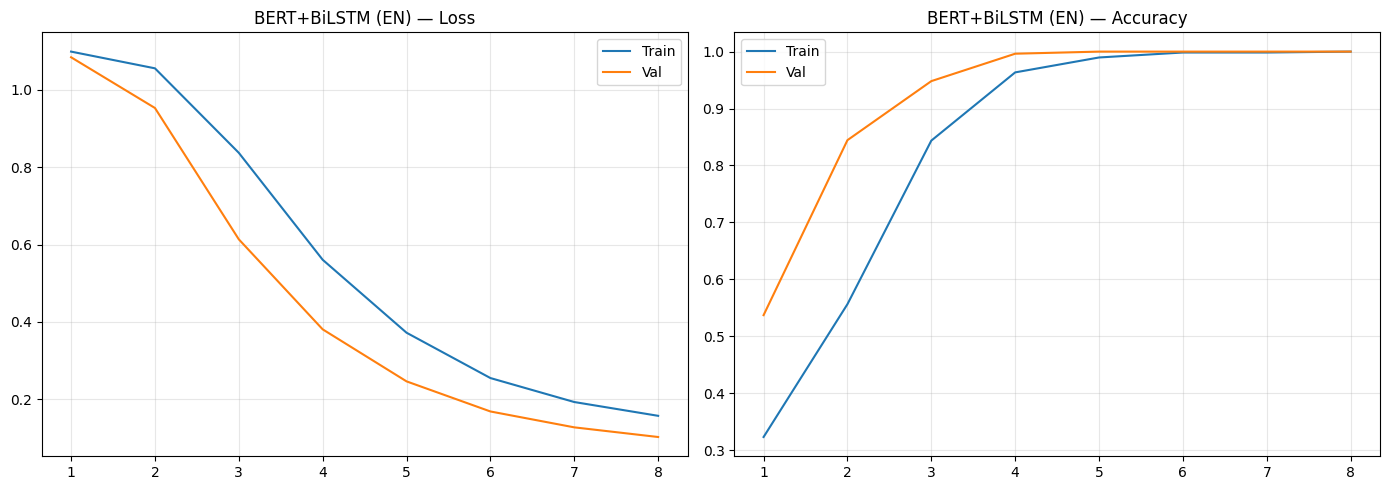

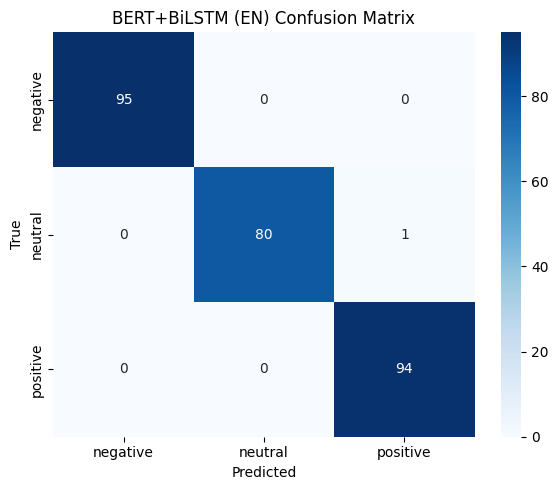

In [9]:
model_bert.load_state_dict(torch.load(f'{RESULTS_DIR}/bert_bilstm_english_best.pt'))
_, acc_bert, f1_bert, preds_bert, labels_bert, probs_bert = evaluate(model_bert, test_dl, criterion, device)
f1w_bert = f1_score(labels_bert, preds_bert, average='weighted')
try:
    auc_bert = roc_auc_score(label_binarize(labels_bert, classes=[0,1,2]), probs_bert, multi_class='ovr', average='macro')
except:
    auc_bert = 0.0

print('=' * 50)
print('BERT+BiLSTM (English) — TEST RESULTS')
print('=' * 50)
print(f'Accuracy: {acc_bert:.4f}  F1(macro): {f1_bert:.4f}  F1(weighted): {f1w_bert:.4f}  AUC-ROC: {auc_bert:.4f}  Time: {bert_time:.1f}s')
print(classification_report(labels_bert, preds_bert, target_names=label_encoder.classes_, digits=4))

# Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, len(history_bert['train_loss'])+1)
axes[0].plot(ep, history_bert['train_loss'], label='Train'); axes[0].plot(ep, history_bert['val_loss'], label='Val')
axes[0].set_title('BERT+BiLSTM (EN) — Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(ep, history_bert['train_acc'], label='Train'); axes[1].plot(ep, history_bert['val_acc'], label='Val')
axes[1].set_title('BERT+BiLSTM (EN) — Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/bert_bilstm_english_training.png', dpi=150, bbox_inches='tight'); plt.show()

cm_bert = confusion_matrix(labels_bert, preds_bert)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm_bert, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=ax)
ax.set_title('BERT+BiLSTM (EN) Confusion Matrix'); ax.set_ylabel('True'); ax.set_xlabel('Predicted')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/bert_bilstm_english_confusion.png', dpi=150, bbox_inches='tight'); plt.show()

## Model 2: RoBERTa (English)

The English-only counterpart to XLM-RoBERTa, with the same classification head on top:

```
Input → roberta-base → [CLS] token → Dense (256, ReLU) → Dropout (0.3) → Softmax (3)
```


In [10]:
class RoBERTaClassifier(nn.Module):
    def __init__(self, model_name='roberta-base', num_classes=3, dropout=0.3):
        super().__init__()
        self.roberta = AutoModel.from_pretrained(model_name)
        for param in self.roberta.parameters():
            param.requires_grad = False
        for param in self.roberta.encoder.layer[-2:].parameters():
            param.requires_grad = True
        hidden_size = self.roberta.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_size, 256)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        cls_out = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(cls_out)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

ROB_MODEL = 'roberta-base'
tokenizer_rob = AutoTokenizer.from_pretrained(ROB_MODEL)
train_dl2, val_dl2, test_dl2 = create_dataloaders(X_train, y_train, X_val, y_val, X_test, y_test, tokenizer_rob, BATCH_SIZE, MAX_LEN)

model_rob = RoBERTaClassifier(ROB_MODEL, NUM_CLASSES).to(device)
optimizer2 = AdamW(filter(lambda p: p.requires_grad, model_rob.parameters()), lr=LR, weight_decay=0.01)
total_steps2 = len(train_dl2) * 10
scheduler2 = get_linear_schedule_with_warmup(optimizer2, int(0.1*total_steps2), total_steps2)

history_rob = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'train_f1': [], 'val_f1': []}
best_f1_rob, patience_ctr2 = 0, 0
start2 = time.time()

for epoch in range(10):
    tl, ta, tf = train_epoch(model_rob, train_dl2, optimizer2, scheduler2, criterion, device)
    vl, va, vf, _, _, _ = evaluate(model_rob, val_dl2, criterion, device)
    history_rob['train_loss'].append(tl); history_rob['val_loss'].append(vl)
    history_rob['train_acc'].append(ta); history_rob['val_acc'].append(va)
    history_rob['train_f1'].append(tf); history_rob['val_f1'].append(vf)
    print(f'Epoch {epoch+1}/10 | TrL:{tl:.4f} TrA:{ta:.4f} TrF1:{tf:.4f} | VL:{vl:.4f} VA:{va:.4f} VF1:{vf:.4f}')
    if vf > best_f1_rob:
        best_f1_rob = vf
        torch.save(model_rob.state_dict(), f'{RESULTS_DIR}/roberta_english_best.pt')
        patience_ctr2 = 0
    else:
        patience_ctr2 += 1
        if patience_ctr2 >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}')
            break

rob_time = time.time() - start2
print(f'\nRoBERTa training: {rob_time:.1f}s')

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 7/10 | TrL:0.0183 TrA:0.9992 TrF1:0.9992 | VL:0.0035 VA:1.0000 VF1:1.0000


Training:   0%|          | 0/40 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 8/10 | TrL:0.0140 TrA:0.9992 TrF1:0.9992 | VL:0.0027 VA:1.0000 VF1:1.0000
Early stopping at epoch 8

RoBERTa training: 138.6s


### Evaluating RoBERTa (English) on the test set


Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

RoBERTa (English) — TEST RESULTS
Accuracy: 0.9963  F1(macro): 0.9962  F1(weighted): 0.9963  AUC-ROC: 1.0000  Time: 138.6s
              precision    recall  f1-score   support

    negative     1.0000    1.0000    1.0000        95
     neutral     1.0000    0.9877    0.9938        81
    positive     0.9895    1.0000    0.9947        94

    accuracy                         0.9963       270
   macro avg     0.9965    0.9959    0.9962       270
weighted avg     0.9963    0.9963    0.9963       270



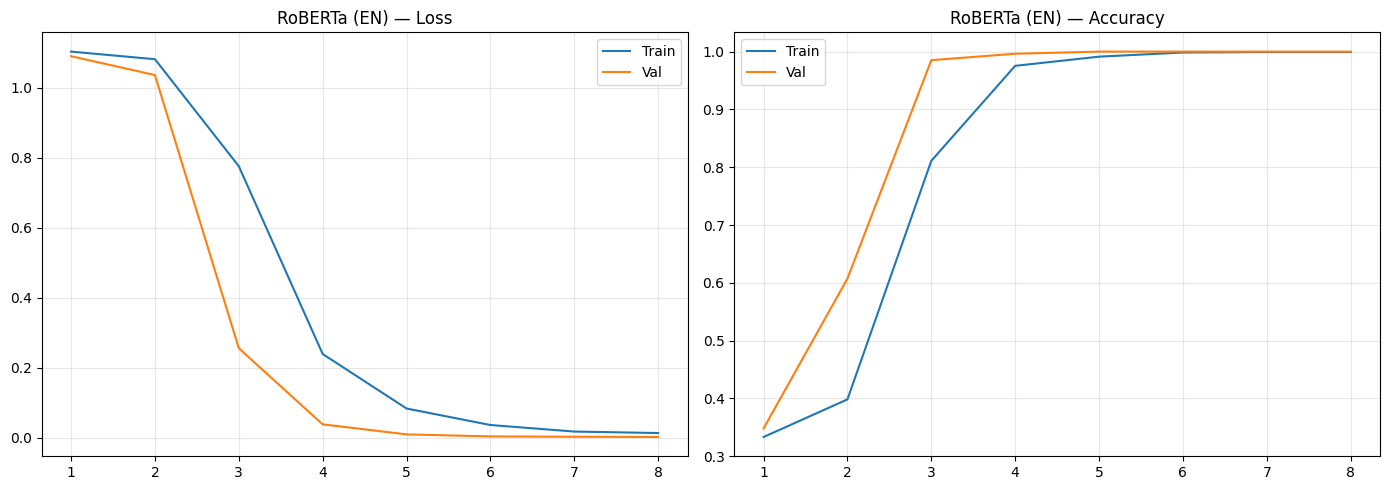

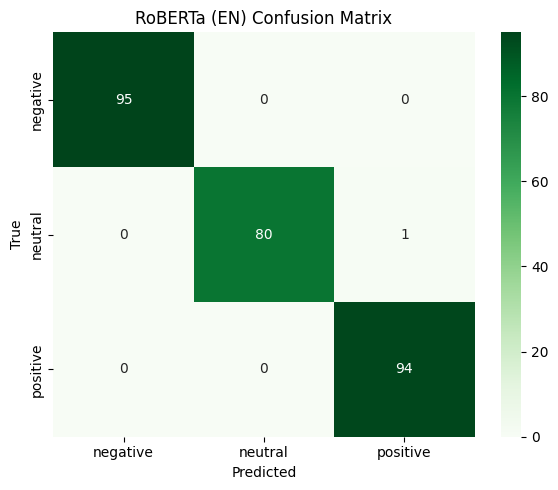

In [11]:
model_rob.load_state_dict(torch.load(f'{RESULTS_DIR}/roberta_english_best.pt'))
_, acc_rob, f1_rob, preds_rob, labels_rob, probs_rob = evaluate(model_rob, test_dl2, criterion, device)
f1w_rob = f1_score(labels_rob, preds_rob, average='weighted')
try:
    auc_rob = roc_auc_score(label_binarize(labels_rob, classes=[0,1,2]), probs_rob, multi_class='ovr', average='macro')
except:
    auc_rob = 0.0

print('=' * 50)
print('RoBERTa (English) — TEST RESULTS')
print('=' * 50)
print(f'Accuracy: {acc_rob:.4f}  F1(macro): {f1_rob:.4f}  F1(weighted): {f1w_rob:.4f}  AUC-ROC: {auc_rob:.4f}  Time: {rob_time:.1f}s')
print(classification_report(labels_rob, preds_rob, target_names=label_encoder.classes_, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep2 = range(1, len(history_rob['train_loss'])+1)
axes[0].plot(ep2, history_rob['train_loss'], label='Train'); axes[0].plot(ep2, history_rob['val_loss'], label='Val')
axes[0].set_title('RoBERTa (EN) — Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(ep2, history_rob['train_acc'], label='Train'); axes[1].plot(ep2, history_rob['val_acc'], label='Val')
axes[1].set_title('RoBERTa (EN) — Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/roberta_english_training.png', dpi=150, bbox_inches='tight'); plt.show()

cm_rob = confusion_matrix(labels_rob, preds_rob)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm_rob, annot=True, fmt='d', cmap='Greens', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=ax)
ax.set_title('RoBERTa (EN) Confusion Matrix'); ax.set_ylabel('True'); ax.set_xlabel('Predicted')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/roberta_english_confusion.png', dpi=150, bbox_inches='tight'); plt.show()

## Overall polarity & saving the results


In [ ]:
def compute_overall_polarity(predictions, class_names):
    unique, counts = np.unique(predictions, return_counts=True)
    count_dict = dict(zip(unique, counts))
    total = len(predictions)
    neg = count_dict.get(list(class_names).index('negative'), 0)
    neu = count_dict.get(list(class_names).index('neutral'), 0)
    pos = count_dict.get(list(class_names).index('positive'), 0)
    neu_pct = neu / total
    if neu_pct > 0.85:
        overall = 'Neutral'
    elif pos > 1.5 * neg:
        overall = 'Positive'
    elif neg > 1.5 * pos:
        overall = 'Negative'
    else:
        overall = 'Neutral'
    return {'overall_polarity': overall, 'positive_count': int(pos), 'negative_count': int(neg), 'neutral_count': int(neu), 'positive_pct': pos/total, 'negative_pct': neg/total, 'neutral_pct': neu_pct}

pol_bert = compute_overall_polarity(preds_bert, label_encoder.classes_)
pol_rob = compute_overall_polarity(preds_rob, label_encoder.classes_)
pol_true = compute_overall_polarity(y_test, label_encoder.classes_)

print(f'Overall Polarity (BERT+BiLSTM EN): {pol_bert["overall_polarity"]}')
print(f'Overall Polarity (RoBERTa EN):     {pol_rob["overall_polarity"]}')
print(f'Overall Polarity (Ground Truth):   {pol_true["overall_polarity"]}')

with open(f'{RESULTS_DIR}/overall_polarity_translated.json', 'w') as f:
    json.dump({'bert_bilstm_en': pol_bert, 'roberta_en': pol_rob, 'ground_truth': pol_true}, f, indent=2)

def save_results(name, fw, acc, f1m, f1w, auc, t, cm, hist, polarity, path):
    r = {'model_name': name, 'framework': fw, 'timestamp': datetime.now().isoformat(),
         'dataset': {'source': 'company_trustpilot_reviews_hard.csv (translated to English)', 'total_samples': len(df_translated), 'train_samples': len(X_train), 'val_samples': len(X_val), 'test_samples': len(X_test), 'num_classes': NUM_CLASSES, 'class_names': list(label_encoder.classes_)},
         'hyperparameters': {'max_len': MAX_LEN, 'batch_size': BATCH_SIZE, 'learning_rate': LR, 'epochs_trained': len(hist['train_loss'])},
         'metrics': {'accuracy': float(acc), 'f1_macro': float(f1m), 'f1_weighted': float(f1w), 'auc_roc_macro': float(auc), 'training_time_seconds': float(t)},
         'confusion_matrix': cm.tolist(), 'training_history': {k: [float(v) for v in vs] for k, vs in hist.items()}, 'overall_polarity_result': polarity}
    with open(path, 'w') as f:
        json.dump(r, f, indent=2)
    print(f'Saved: {path}')

save_results('BERT+BiLSTM (English)', 'PyTorch/HuggingFace', acc_bert, f1_bert, f1w_bert, auc_bert, bert_time, cm_bert, history_bert, pol_bert, f'{RESULTS_DIR}/bert_bilstm_english_results.json')
save_results('RoBERTa (English)', 'PyTorch/HuggingFace', acc_rob, f1_rob, f1w_rob, auc_rob, rob_time, cm_rob, history_rob, pol_rob, f'{RESULTS_DIR}/roberta_english_results.json')

Overall Polarity (BERT+BiLSTM EN): Neutral
Overall Polarity (RoBERTa EN):     Neutral
Overall Polarity (Ground Truth):   Neutral
Saved: /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Translated/bert_bilstm_english_results.json
Saved: /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Translated/roberta_english_results.json


## Comparing the two models



TRANSLATED APPROACH — COMPARISON SUMMARY
Model                          Accuracy     F1(macro)    AUC-ROC      Time(s)   
----------------------------------------------------------------------
BERT+BiLSTM (EN)               0.9963       0.9962       0.9999       122.4     
RoBERTa (EN)                   0.9963       0.9962       1.0000       138.6     


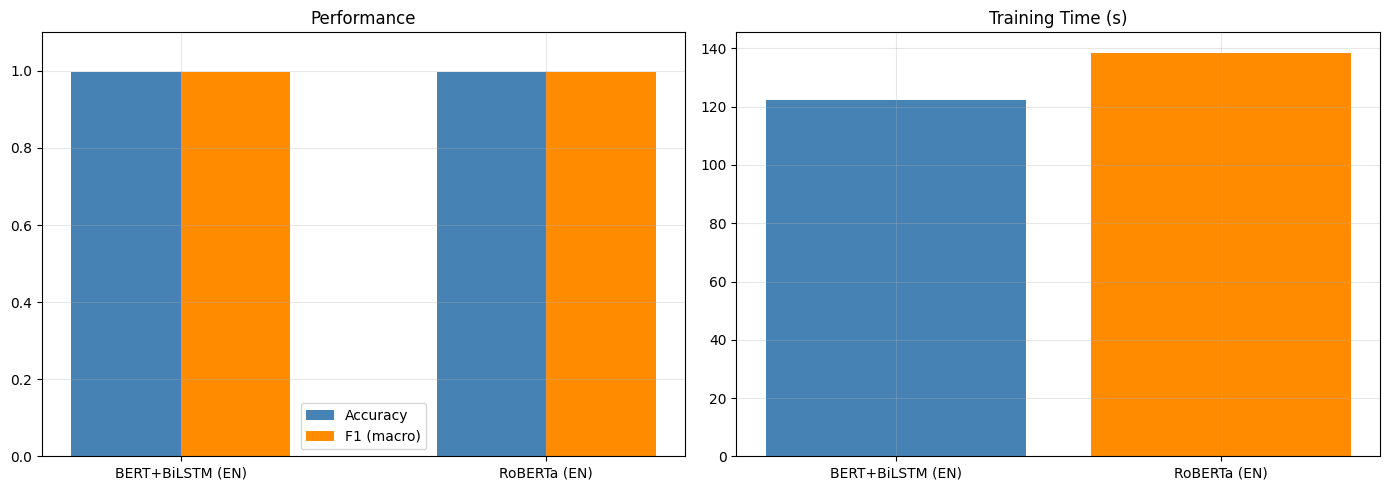


✅ Notebook 2 complete. All results saved to Results_Translated/


In [13]:
print('\n' + '=' * 70)
print('TRANSLATED APPROACH — COMPARISON SUMMARY')
print('=' * 70)
print(f'{"Model":<30} {"Accuracy":<12} {"F1(macro)":<12} {"AUC-ROC":<12} {"Time(s)":<10}')
print('-' * 70)
print(f'{"BERT+BiLSTM (EN)":<30} {acc_bert:<12.4f} {f1_bert:<12.4f} {auc_bert:<12.4f} {bert_time:<10.1f}')
print(f'{"RoBERTa (EN)":<30} {acc_rob:<12.4f} {f1_rob:<12.4f} {auc_rob:<12.4f} {rob_time:<10.1f}')
print('=' * 70)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models = ['BERT+BiLSTM (EN)', 'RoBERTa (EN)']
x = np.arange(len(models))
axes[0].bar(x - 0.15, [acc_bert, acc_rob], 0.3, label='Accuracy', color='steelblue')
axes[0].bar(x + 0.15, [f1_bert, f1_rob], 0.3, label='F1 (macro)', color='darkorange')
axes[0].set_xticks(x); axes[0].set_xticklabels(models)
axes[0].set_ylim(0, 1.1); axes[0].set_title('Performance'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].bar(models, [bert_time, rob_time], color=['steelblue', 'darkorange'])
axes[1].set_title('Training Time (s)'); axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/translated_comparison.png', dpi=150, bbox_inches='tight'); plt.show()
print('\n✅ Notebook 2 complete. All results saved to Results_Translated/')